In [1]:
from pathlib import Path
import os, sys, sqlite3, pandas as pd

PROSJEKT = Path.cwd()
if PROSJEKT.name == "notebooks":
    PROSJEKT = PROSJEKT.parent
os.chdir(PROSJEKT)
if str(PROSJEKT) not in sys.path:
    sys.path.insert(0, str(PROSJEKT))

from src.kunstpixel.core import db  # Ferdige fasit-kalkulatorer (lønn, overtid, sykefravær)

con = sqlite3.connect("file:05_data/museum.db?mode=ro", uri=True)   # mode=ro: kan ikke endre databasen
sql = lambda q: pd.read_sql(q, con)
sql("select name from sqlite_master where type='table' order by name")

,name
0,arbeidstid_grenser
1,arbeidstilsynet_renhold
2,avvik_hms_drift
3,dagsbesok
4,handbok_oppslag
5,hendelser
6,hms_ergonomi_rotasjon
7,hr_ansatte
8,hr_availability
9,hr_fravaer


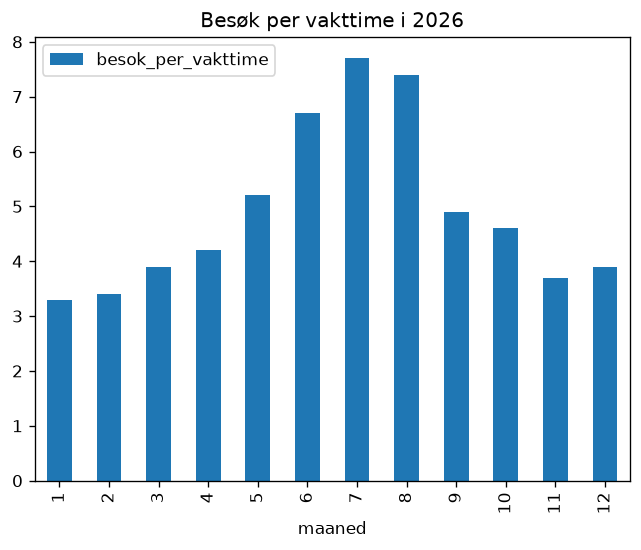

,maaned,besok,vakter,timer,besok_per_vakttime
0,1,6885,278,2101.5,3.3
1,2,6410,248,1883.0,3.4
2,3,7948,270,2048.5,3.9
3,4,8600,268,2044.5,4.2
4,5,11026,278,2102.5,5.2
5,6,13181,260,1968.5,6.7
6,7,16276,278,2103.5,7.7
7,8,15003,270,2040.0,7.4
8,9,10082,268,2046.5,4.9
9,10,9644,278,2105.5,4.6


In [2]:
df = sql("""
select d.maaned, sum(d.besok_totalt) as besok, v.vakter, v.timer
from dagsbesok d
join (select maaned, count(*) as vakter, sum(timer) as timer from hr_vakter where aar = 2026 group by maaned) v using (maaned)
where d.aar = 2026 and d.er_aapent = 1
group by d.maaned order by d.maaned
""")
df["besok_per_vakttime"] = (df.besok / df.timer).round(1)
df.plot(x="maaned", y="besok_per_vakttime", kind="bar", title="Besøk per vakttime i 2026")
df

In [3]:
# Bruker samme fasit-kalkulator som nettsiden (Datafinner), slik at kronebeløpene alltid er 100 % like
kost = db.query_shift_cost("2026-05")
df_kost = pd.DataFrame(kost["avdelinger"])
df_kost

,avdeling,vakter,timer,kveldstimer,vakter_uten_tariff,kostnad_nok
0,Formidling,145,1098.5,18.5,0,508364.25
1,Marked,71,536.5,20.0,0,252134.62
2,Drift,40,300.0,49.5,0,146088.36
3,Samling,22,167.5,3.0,0,77209.03


## 4. Åpent punkt G7: Dager i 2026 med mange besøkende, men få vakter
Regelen `R-VAKT-01` i `05_data/rapport_regler.csv` krever **minst 8 på vakt** for full stasjonsdekning (`R-PLAN-01` krever minst 6).
Tabellen og grafen under kobler `dagsbesok` mot `hr_vakter` per åpen dag i 2026 for å vise hvor bemanningspresset er størst før vi eventuelt utvider datasettet.

Åpne dager i 2026: 313 | Snitt vakter/dag: 10.0 | Dager under 8 vakter (R-VAKT-01): 0 (0.0%) | Dager under 6 vakter (R-PLAN-01): 0


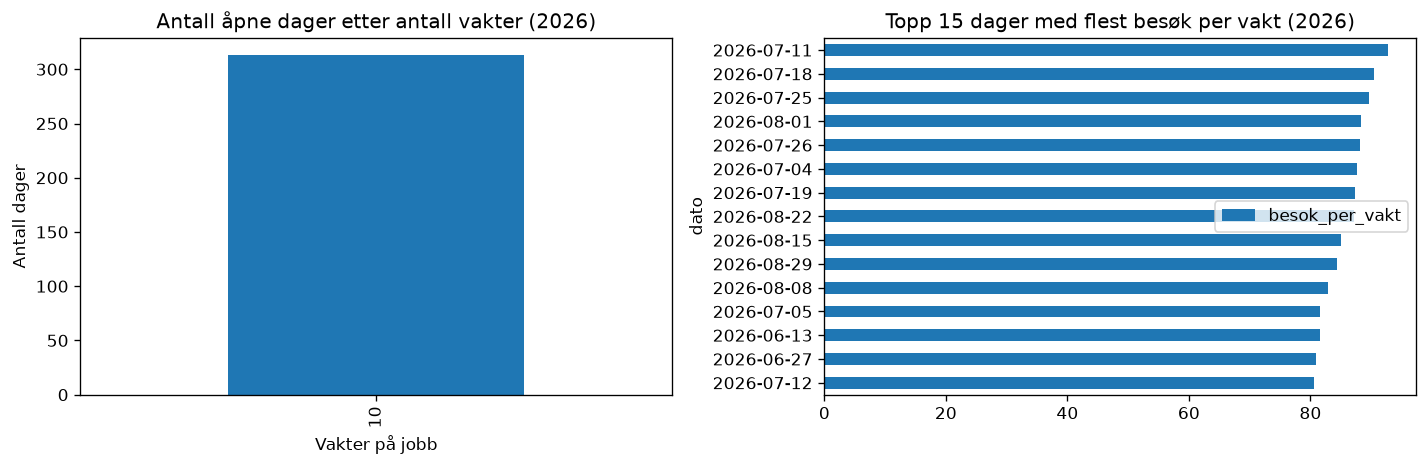

,dato,ukedag,maaned,besok_totalt,vakter,vakttimer,besok_per_vakt
0,2026-07-11,Lørdag,7,928,10,75.0,92.8
1,2026-07-18,Lørdag,7,904,10,77.0,90.4
2,2026-07-25,Lørdag,7,896,10,78.0,89.6
3,2026-08-01,Lørdag,8,884,10,75.0,88.4
4,2026-07-26,Søndag,7,882,10,75.0,88.2
5,2026-07-04,Lørdag,7,876,10,77.0,87.6
6,2026-07-19,Søndag,7,874,10,75.0,87.4
7,2026-08-22,Lørdag,8,871,10,75.0,87.1
8,2026-08-15,Lørdag,8,850,10,75.0,85.0
9,2026-08-29,Lørdag,8,843,10,75.0,84.3


In [4]:
import matplotlib.pyplot as plt
# G7: Koble dagsbesøk og antall vakter per åpen dag i 2026
df_g7 = sql("""
select d.dato, d.ukedag_navn as ukedag, d.maaned, d.besok_totalt,
       coalesce(v.vakter, 0) as vakter,
       coalesce(v.timer, 0) as vakttimer,
       round(1.0 * d.besok_totalt / nullif(v.vakter, 0), 1) as besok_per_vakt
from dagsbesok d
left join (
    select dato, count(*) as vakter, sum(timer) as timer
    from hr_vakter where aar = '2026' group by dato
) v using (dato)
where d.aar = 2026 and d.er_aapent = 1
order by besok_per_vakt desc
""")

print(f"Åpne dager i 2026: {len(df_g7)} | Snitt vakter/dag: {df_g7['vakter'].mean():.1f} | "
      f"Dager under 8 vakter (R-VAKT-01): {(df_g7['vakter'] < 8).sum()} ({(df_g7['vakter'] < 8).mean()*100:.1f}%) | "
      f"Dager under 6 vakter (R-PLAN-01): {(df_g7['vakter'] < 6).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_g7['vakter'].value_counts().sort_index().plot(kind='bar', ax=axes[0], title='Antall åpne dager etter antall vakter (2026)')
axes[0].axvline(x=1.5, color='red', linestyle='--', label='Terskel 8 vakter (R-VAKT-01)')
axes[0].set_xlabel('Vakter på jobb')
axes[0].set_ylabel('Antall dager')

df_g7.head(15).plot(x='dato', y='besok_per_vakt', kind='barh', ax=axes[1], title='Topp 15 dager med flest besøk per vakt (2026)')
axes[1].invert_yaxis()
plt.tight_layout()

df_g7.head(15)